<h1 align="center">Rwanda Maize–Urea Trial</h1>
<h2 align="center">3. Exploratory Data Analysis & Field Map</h2>

**Goal:** see how yield varies by treatment, season and mega-environment before modelling, and map the trial fields (Objective 4).

Raw averages here ignore the fact that plots share fields. The adjusted comparison is in notebook 04.

> **Data note.** The trial data is confidential and is not in this repository. The outputs shown were produced on the real data. If you run this notebook without it, it uses the synthetic sample in `01_Data/sample/` and the numbers will differ.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "02_Notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from maize import config, data, mapping, plotting

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)
MODE = config.data_mode()
OUT = config.output_paths(MODE)
print("Data source:", "confidential trial data (01_Data/raw)" if MODE == "raw" else "synthetic sample (01_Data/sample)")

Data source: confidential trial data (01_Data/raw)


In [2]:
_, combined = data.build_combined(MODE)
df = data.analysis_frame(combined)
ok = df[~df["flag_implausible_yield"]]
print(f"{len(df)} plots with field context; {len(ok)} after setting aside the implausible yield")

1593 plots with field context; 1592 after setting aside the implausible yield


## 1. Yield by treatment

In [3]:
(ok.groupby("urea_rate_timing", observed=True)["yield_tha"]
   .agg(plots="size", mean="mean", median="median", sd="std")
   .rename(index=config.TREATMENT_LABELS))

,plots,mean,median,sd
urea_rate_timing,,,,
"A: 50 kg/ha, all at V6",399,4.570,4.550,1.760
"B: 100 kg/ha, planting + V6",396,4.716,4.685,1.877
"C: 100 kg/ha, V6 + V10",398,4.957,4.970,1.852
"D: 100 kg/ha, all at V6",399,5.116,5.220,1.913


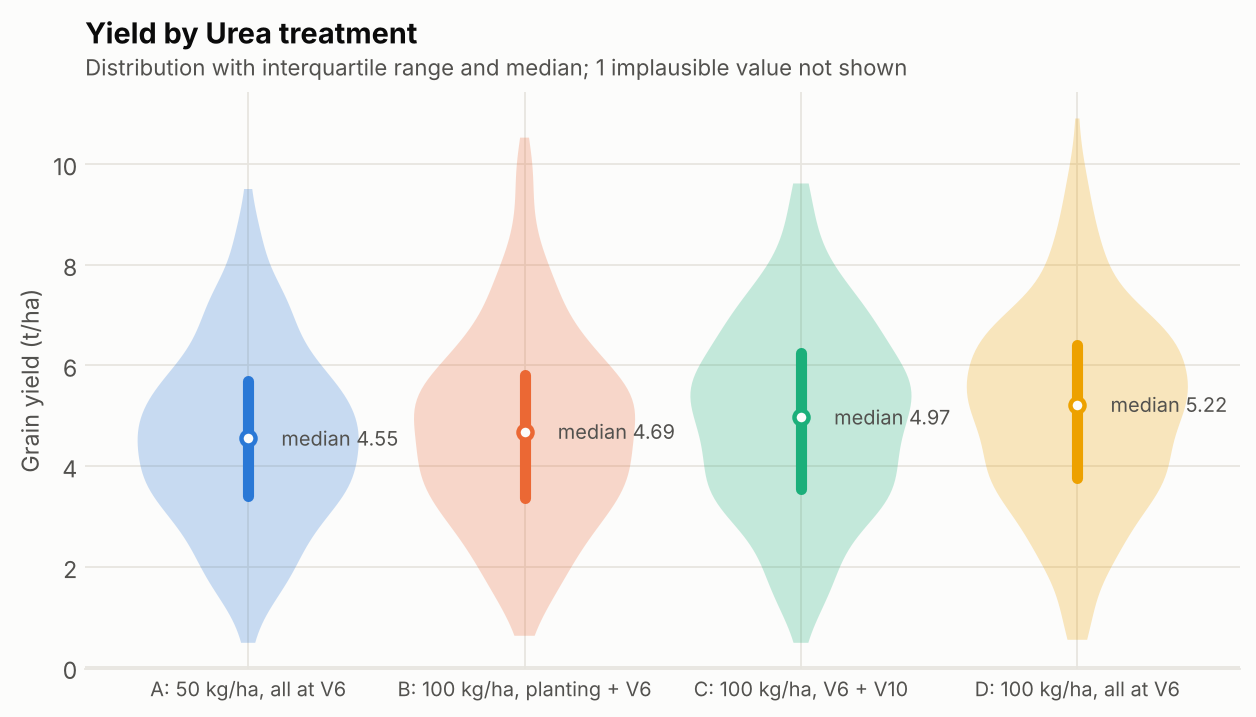

In [4]:
plotting.yield_by_treatment(df, OUT.figures / "yield_by_treatment.png")
display(Image(OUT.figures / "yield_by_treatment.png", width=700))

Both treatments that apply 100 kg/ha at V6 or later (C and D) sit visibly higher than the baseline. Splitting with a planting dose (B) barely moves the distribution. The spread within each treatment (SD about 1.8–1.9 t/ha) is much larger than the gaps between them, which is why a model that accounts for field differences is needed.

## 2. By season

In [5]:
(ok.pivot_table(index="season", columns="urea_rate_timing", values="yield_tha", aggfunc="mean", observed=True)
   .rename(columns=config.SHORT_LABELS))

urea_rate_timing,A · 50 kg V6,B · 100 kg Plant+V6,C · 100 kg V6+V10,D · 100 kg V6
season,,,,
21A,4.299,4.431,4.775,4.851
22A,4.888,5.052,5.188,5.388
22B,4.229,4.350,4.682,4.876


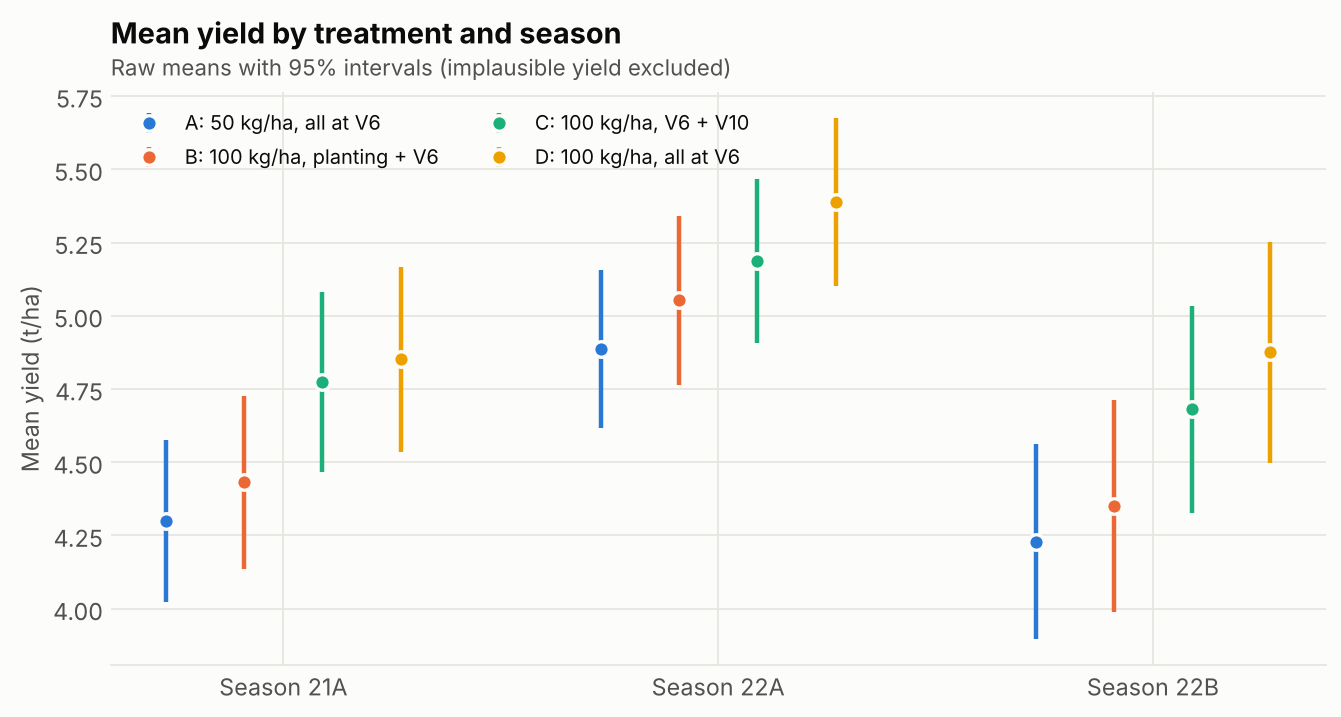

In [6]:
plotting.yield_by_treatment_season(df, OUT.figures / "yield_by_treatment_and_season.png")
display(Image(OUT.figures / "yield_by_treatment_and_season.png", width=720))

The ranking is consistent across seasons: D and C on top, A at the bottom, and B close to A. 22A was the best season overall.

## 3. By mega-environment

In [7]:
(ok.pivot_table(index="meg_env", columns="urea_rate_timing", values="yield_tha", aggfunc="mean", observed=True)
   .rename(columns=config.SHORT_LABELS)
   .assign(fields=ok.groupby("meg_env")["field_season_id"].nunique()))

urea_rate_timing,A · 50 kg V6,B · 100 kg Plant+V6,C · 100 kg V6+V10,D · 100 kg V6,fields
meg_env,,,,,
Highlands,4.177,4.289,4.536,4.663,142
Low-Mid-Dry,5.687,5.773,6.032,6.186,115
Low-Mid-Wet,3.893,4.315,4.675,4.698,77
Transitional,4.254,4.236,4.324,4.707,65


Low-Mid-Dry fields yield about 1.5 t/ha more than the others regardless of treatment. Within every environment the 100 kg/ha treatments applied at V6 or later lead. Notebook 04 tests whether these differences are significant.

## 4. Map of trial fields (Objective 4)

Published maps round coordinates to 2 decimal places (~1 km) to protect farmers. An exact map is written only to the git-ignored `01_Data/processed/` folder.

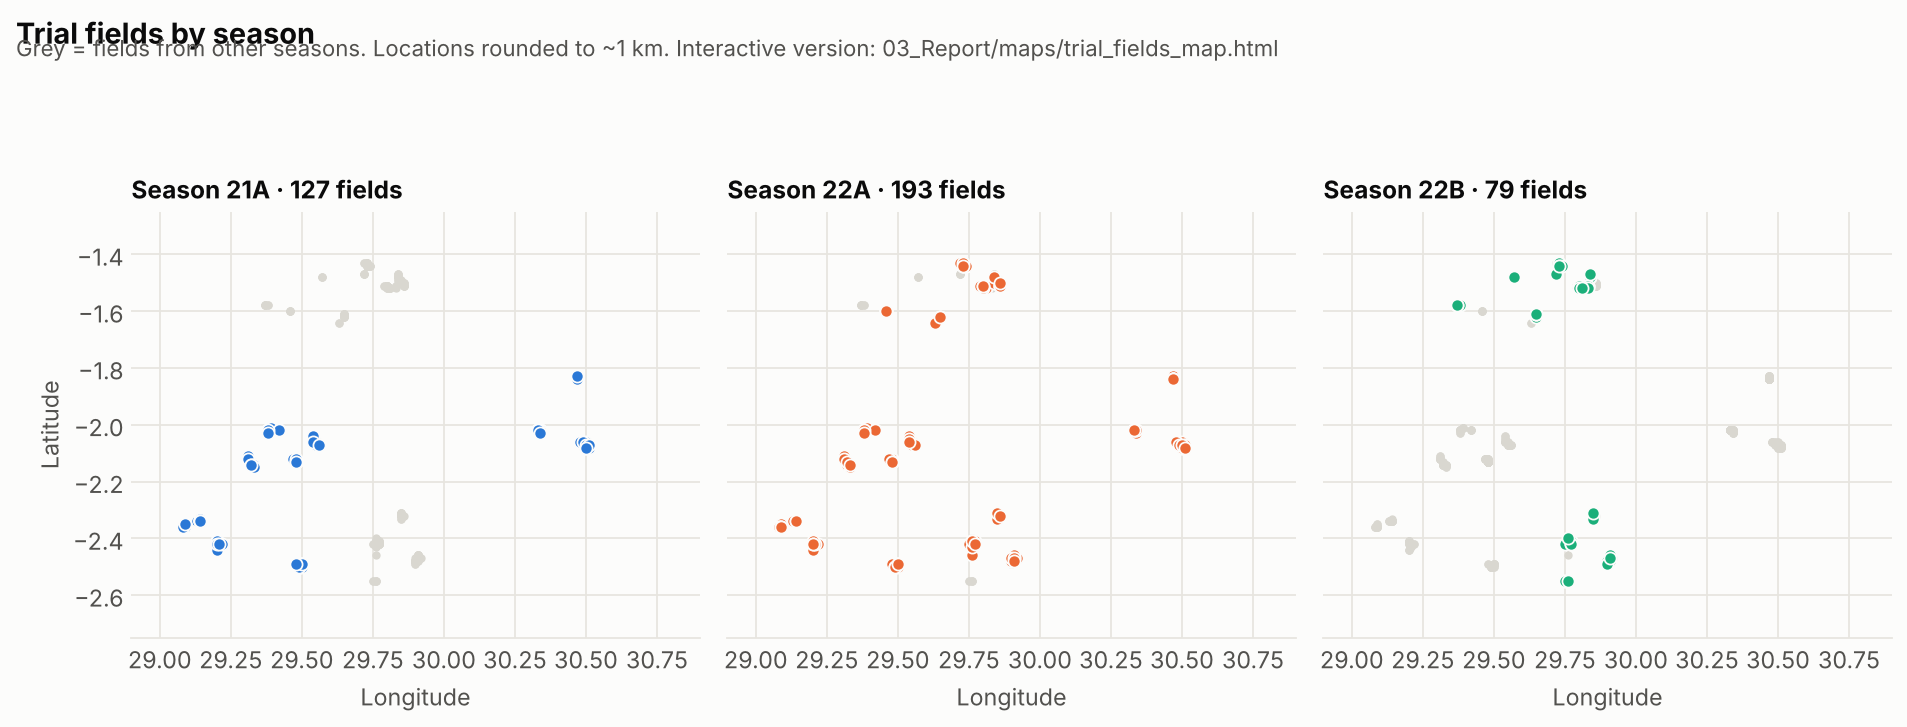

,fields,districts
season,,
21A,127,7
22A,193,13
22B,79,6


In [8]:
mapping.static_map(combined, OUT.figures / "trial_fields_map.png")
mapping.interactive_map(combined, OUT.maps / "trial_fields_map.html")
display(Image(OUT.figures / "trial_fields_map.png", width=900))
mapping.field_points(combined).groupby("season").agg(fields=("district", "size"), districts=("district", "nunique"))

The interactive version ([`03_Report/maps/trial_fields_map.html`](../03_Report/maps/trial_fields_map.html)) lets you toggle seasons and hover for district, environment and median yield.

Season 22B has no fields in the Eastern Ridges, which is worth remembering when interpreting season effects.

**Next:** notebook 04 estimates the treatment effects properly.